# 01 — Évaluation des modèles de référence

**Question** : que valent les modèles d'origine du projet, et où se trompent-ils ?

**Modèles évalués**
- `baseline-stars` : `cmarkea/distilcamembert-base-sentiment` (5 étoiles regroupées : 1-2★ → négatif, 3★ → neutre, 4-5★ → positif) — le modèle utilisé par l'API à l'origine ;
- `tfidf-fallback` : TF-IDF + régression logistique (modèle de secours).

**Jeux de test**
- `textsense_eval_v1` : 360 phrases du projet, 120 par classe, cas difficiles annotés ([fiche](../data/eval/DATASHEET.md)) ;
- `tweets_fr_test` : 870 tweets français annotés en 3 classes (jeu public, autre domaine).

Les chiffres viennent de `reports/eval/` (produits par `make eval-baselines`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
REPORTS = ROOT / "reports"
pd.set_option("display.precision", 3)


def load_metrics(run, dataset):
    path = REPORTS / "eval" / run / dataset / "metrics.json"
    return json.loads(path.read_text())["metrics"] if path.exists() else None


def overview(runs, datasets):
    rows = []
    for run in runs:
        for dataset in datasets:
            m = load_metrics(run, dataset)
            if m is None:
                continue
            low, high = m["ci95"]["macro_f1"]
            rows.append({
                "modèle": run, "jeu": dataset, "macro-F1": m["macro_f1"],
                "IC 95 %": f"[{low:.3f} – {high:.3f}]", "exactitude": m["accuracy"],
                "F1 nég.": m["per_class"]["negative"]["f1"],
                "F1 neutre": m["per_class"]["neutral"]["f1"],
                "F1 pos.": m["per_class"]["positive"]["f1"], "ECE": m["ece"],
            })
    return pd.DataFrame(rows).set_index(["jeu", "modèle"]).sort_index()


def by_phenomenon(runs):
    data = {}
    for run in runs:
        m = load_metrics(run, "textsense_eval_v1")
        if m:
            data[run] = {k: v["accuracy"] for k, v in m["by_group"]["phenomenon"].items()}
    df = pd.DataFrame(data)
    counts = load_metrics(runs[0], "textsense_eval_v1")["by_group"]["phenomenon"]
    df.insert(0, "n", [counts[p]["n"] for p in df.index])
    return df


## Vue d'ensemble

Métrique principale : **macro-F1** (chaque classe compte autant).

In [2]:
overview(["baseline-stars", "tfidf-fallback"], ["textsense_eval_v1", "tweets_fr_test"])

macro-F1          IC 95 %  exactitude  \
jeu               modèle                                                  
textsense_eval_v1 baseline-stars     0.510  [0.480 – 0.541]       0.617   
                  tfidf-fallback     0.513  [0.462 – 0.564]       0.542   
tweets_fr_test    baseline-stars     0.363  [0.335 – 0.390]       0.438   
                  tfidf-fallback     0.264  [0.238 – 0.292]       0.341   

                                  F1 nég.  F1 neutre  F1 pos.    ECE  
jeu               modèle                                              
textsense_eval_v1 baseline-stars    0.805      0.031    0.694  0.154  
                  tfidf-fallback    0.481      0.651    0.407  0.033  
tweets_fr_test    baseline-stars    0.507      0.052    0.529  0.167  
                  tfidf-fallback    0.244      0.465    0.082  0.175

## Matrices de confusion

Lignes = vraie classe, colonnes = prédiction. Pourcentages par ligne (rappel).

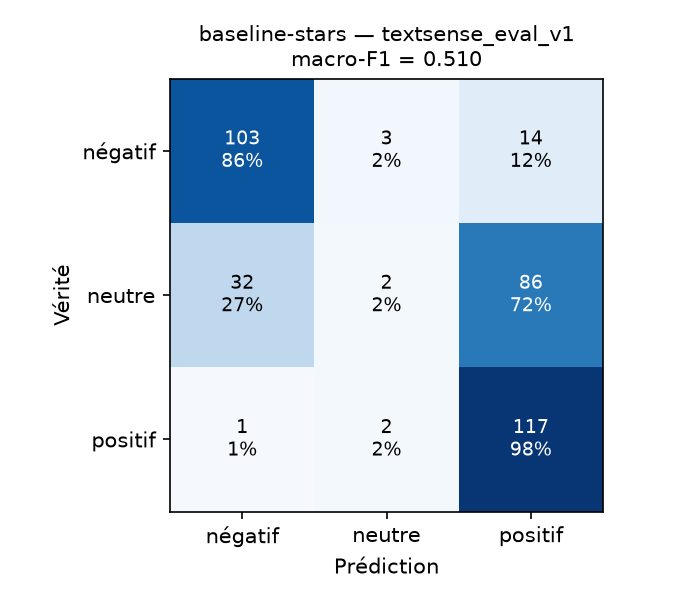

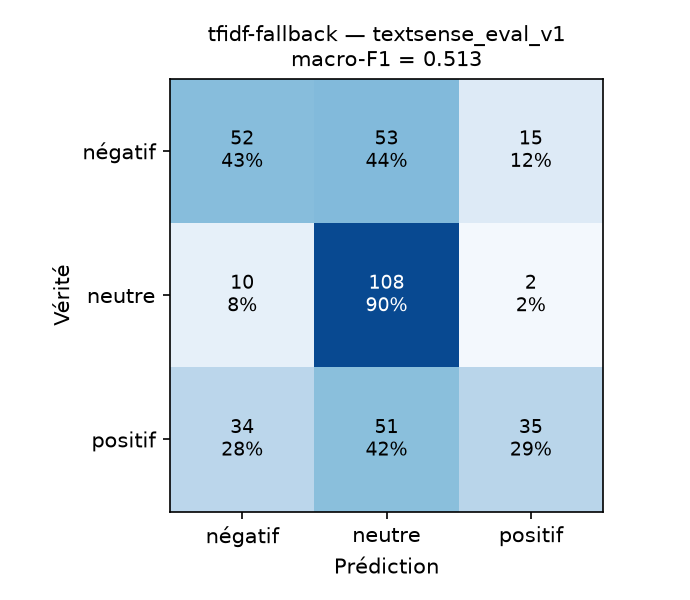

In [3]:
for run in ["baseline-stars", "tfidf-fallback"]:
    display(Image(filename=str(REPORTS / "eval" / run / "textsense_eval_v1" / "confusion_matrix.png"), width=360))

## Exactitude par phénomène linguistique

Sur 10 à 45 exemples par ligne : ce sont des **tendances**, pas des mesures précises.

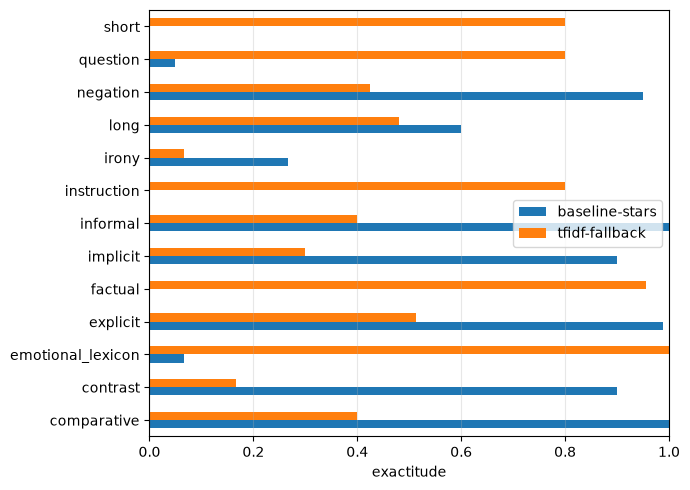

,n,baseline-stars,tfidf-fallback
comparative,10,1.000,0.400
contrast,30,0.900,0.167
emotional_lexicon,15,0.067,1.000
explicit,80,0.988,0.512
factual,45,0.000,0.956
implicit,30,0.900,0.300
informal,20,1.000,0.400
instruction,20,0.000,0.800
irony,15,0.267,0.067
long,25,0.600,0.480


In [4]:
table = by_phenomenon(["baseline-stars", "tfidf-fallback"])
ax = table.drop(columns='n').plot.barh(figsize=(7, 5))
ax.set_xlabel("exactitude"); ax.set_xlim(0, 1); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()
table

## Analyse d'erreurs : où va la classe neutre ?

In [5]:
pred = pd.read_csv(REPORTS / "eval" / "baseline-stars" / "textsense_eval_v1" / "predictions.csv")
neutral = pred[pred.label == "neutral"]
display(neutral.pred.value_counts().rename("prédictions pour les 120 phrases neutres").to_frame())
neutral[neutral.pred != "neutral"].sort_values("confidence", ascending=False)[["text", "phenomenon", "pred", "confidence"]].head(10)

,prédictions pour les 120 phrases neutres
pred,
positive,86
negative,32
neutral,2


,text,phenomenon,pred,confidence
343,Le logiciel comprend trois modules : la gestio...,long,positive,0.883
324,Mettez à jour l'application pour accéder aux n...,instruction,positive,0.843
342,Le musée présente une collection de peintures ...,long,positive,0.778
258,Le service client est joignable par téléphone ...,factual,positive,0.775
276,La conférence sera retransmise en direct sur l...,factual,positive,0.719
255,La nouvelle version du logiciel a été publiée ...,factual,positive,0.711
265,Le serveur redémarre automatiquement chaque nu...,factual,negative,0.704
250,"Ce modèle existe en trois coloris : noir, blan...",factual,positive,0.681
347,Le patient doit être à jeun depuis la veille a...,long,positive,0.679
320,Rangez le matériel après chaque utilisation.,instruction,positive,0.676


## Conclusions

- Le modèle « étoiles » est **très bon en positif / négatif** (négations, contrastes) mais **ne prédit presque jamais neutre** : une information factuelle ou une question n'est pas un avis, et la note « 3 étoiles » ne correspond pas à « pas d'opinion ». Les phrases neutres partent massivement en positif.
- Le modèle TF-IDF fait l'erreur inverse : il range beaucoup de textes en neutre, et ne comprend ni la négation ni le contraste.
- Le défaut est **structurel** (mauvaise définition de la classe neutre), pas un problème de seuil : il faut un modèle entraîné **directement en 3 classes** → notebook 02.